# Regridding: ERA5 2 m temperature on the global IFS 0.1° grid

This example illustrates {func}`~grid_process.grid_interp.interp2grid` on the whole globe with three
methods:

- `nearest`: value of the nearest source grid point;
- `linear`: bilinear interpolation on the regular latitude/longitude grid;
- `temp_fixgrad`: among the source grid points within `r_search` grid spacings, the one with the most
  similar altitude, corrected for the remaining altitude difference with a fixed lapse rate
  (6 K/km by default).

The 2 m temperature of the ERA5 reanalysis (regular 0.25° grid, about 28 km, 1.04 million points) at a
single time is regridded to the global 0.1° grid of the IFS open data (about 9 km, 6.5 million cells),
whose orography resolves the mountains in much more detail.

Both grids are in latitude/longitude and cover the globe, so the nearest neighbor searches of `nearest`
(with `try_reg=False`) and `temp_fixgrad` run in earth-centered earth-fixed coordinates (ECEF): distances
are measured in meters through the Earth, so they are correct everywhere, across the antimeridian and at
the poles.

Running this notebook needs a free account on the
[Copernicus Climate Data Store](https://cds.climate.copernicus.eu): your API token in `~/.cdsapirc`
and the licence of the ERA5 dataset accepted once on its download page. It uses about 8 GB of memory.

*Data: contains modified Copernicus Climate Change Service information 2026, ERA5 hourly data on single
levels (DOI: 10.24381/cds.adbb2d47), CC BY 4.0. ECMWF open data, © ECMWF, CC BY 4.0. Coastlines: Natural
Earth.*

In [1]:
import contextlib
import io
import logging
import re
import time
import timeit
from collections.abc import Callable
from functools import partial
from typing import Any

# import pyproj before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import pyproj  # noqa: F401  # pylint: disable=unused-import

import cartopy.crs as ccrs
import earthkit.data as ekd
import earthkit.plots as ekp
import geopandas as gpd
import numpy as np
import pandas as pd
import requests
import xarray as xr
from requests.adapters import HTTPAdapter
from urllib3.util import Retry

import grid_process.grid_interp as gri
import grid_process.units_conv as uconv

METHODS: dict[str, dict[str, Any]] = {
    "nearest": {"method": "nearest"},
    "linear": {"method": "linear"},
    "temp_fixgrad": {"method": "temp_fixgrad"},
}
ERA5_TIME = "2025-01-15T12:00"  # single time of the ERA5 reanalysis
# zooms on mountain regions: (longitude, latitude) bounds
REGIONS = {
    "Himalaya": ((75.0, 100.0), (40.0, 25.0)),
    "Andes": ((-80.0, -60.0), (-10.0, -35.0)),
    "Alps": ((5.0, 16.5), (48.5, 43.5)),
}

## Destination grid

The destination grid is the global 0.1° latitude/longitude grid of the IFS open data (3600 × 1801 cells,
longitudes from -180° to 180°). Its orography, the surface geopotential `z` at step 0, gives the
altitude in a `surface_altitude` coordinate, which `temp_fixgrad` needs. The grid is fixed, so any run
does: we take the latest one on the ECMWF open data portal.

In [2]:
OD_ROOT = "https://data.ecmwf.int/forecasts"

# the portal sometimes times out: retry with an increasing delay (earthkit already retries the field downloads)
session = requests.Session()
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retry))
# hide the notice about the connection limit of the portal that the ECMWF open data client logs
logging.getLogger("ecmwf.opendata.utils").addFilter(lambda record: "500 simultaneous" not in record.getMessage())


def index_url(day: str, hour: int, step: int) -> str:
    return f"{OD_ROOT}/{day}/{hour:02d}z/ifs/0p1/oper/{day}{hour:02d}0000-{step}h-oper-fc-sfc.index"


def list_days() -> list[str]:
    """Days with forecasts on the portal, oldest first."""
    return sorted(set(re.findall(r'href="/forecasts/(\d{8})/"', session.get(f"{OD_ROOT}/", timeout=30).text)))


def latest_ifs_run(step: int) -> tuple[str, int]:
    """Latest IFS-HRES run on the ECMWF open data portal with the given step already published."""
    for day in reversed(list_days()):
        for hour in (18, 12, 6, 0):
            if session.head(index_url(day, hour, step), timeout=30).ok:
                return day, hour
    raise RuntimeError("No IFS-HRES run found on the open data portal")


run_date, run_hour = latest_ifs_run(0)
# hide the download progress bars that earthkit always shows on stderr
with contextlib.redirect_stderr(io.StringIO()):
    z_surf = ekd.from_source(
        "ecmwf-open-data",
        model="ifs",
        resol="0p1",
        stream="oper",
        type="fc",
        date=int(run_date),
        time=run_hour,
        param="z",
        levtype="sfc",
        step=0,
    ).to_xarray()["z"]
z_surf = z_surf.squeeze().reset_coords(drop=True)
dst_grid = xr.Dataset(
    coords={"surface_altitude": (z_surf / 9.80665).astype("float32").assign_attrs(units="m")},
    attrs={"crs": "EPSG:4326"},
)
print(f"IFS-HRES run {run_date} {run_hour:02d} UTC (orography only)")
dst_grid

IFS-HRES run 20261109 12 UTC (orography only)


<xarray.Dataset> Size: 26MB
Dimensions:           (latitude: 1801, longitude: 3600)
Coordinates:
  * latitude          (latitude) float64 14kB 90.0 89.9 89.8 ... -89.9 -90.0
  * longitude         (longitude) float64 29kB -180.0 -179.9 ... 179.8 179.9
    surface_altitude  (latitude, longitude) float32 26MB 0.2591 ... 2.765e+03
Data variables:
    *empty*
Attributes:
    crs:      EPSG:4326

## Source data

The ERA5 2 m temperature and its orography (the surface geopotential `z`) are retrieved from the Climate
Data Store for a single time, on the regular 0.25° grid of the CDS (721 × 1440 points). ERA5 longitudes
run from 0° to 360°, those of the destination grid from -180° to 180°: `grid_process` handles both
conventions, including across the 360° seam of the source grid.

In [3]:
request = {
    "product_type": ["reanalysis"],
    "variable": ["2m_temperature", "geopotential"],
    "date": [ERA5_TIME[:10]],
    "time": [ERA5_TIME[11:]],
    "data_format": "netcdf",
    "download_format": "unarchived",
}
era5 = ekd.from_source("cds", "reanalysis-era5-single-levels", request).to_xarray()
era5 = era5.squeeze("valid_time").reset_coords(drop=True)

ds = uconv.ds_to(era5[["t2m"]], {"t2m": "degC"})
ds = ds.assign_coords(surface_altitude=(era5["z"] / 9.80665).astype("float32").assign_attrs(units="m"))
ds

<xarray.Dataset> Size: 8MB
Dimensions:           (latitude: 721, longitude: 1440)
Coordinates:
  * latitude          (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude         (longitude) float64 12kB 0.0 0.25 0.5 ... 359.5 359.8
    surface_altitude  (latitude, longitude) float32 4MB -0.1264 ... 2.826e+03
Data variables:
    t2m               (latitude, longitude) float32 4MB -27.09 -27.09 ... -26.01
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-09T20:06 GRIB to CDM+CF via cfgrib-0.9.1...

## Interpolation

Each method is called once, and the duration of this first call is kept for the benchmark below. On a
regular grid with 1D coordinates, `nearest` and `linear` use xarray's interpolation by default
(`try_reg=True`), in latitude and longitude. `nearest` is also run through the generic path
(`try_reg=False`), which searches the nearest source grid point in ECEF coordinates. On a regular grid
both select the same point: a destination cell lies in one source grid box, and the corner closest in
latitude and in longitude is also the closest one on the sphere. The generic path matters for the
methods using a neighborhood (e.g. `idw`, `temp_fixgrad`), whose extent must be measured in meters,
and for irregular grids. `linear` cannot triangulate points on a sphere in ECEF: on global
latitude/longitude grids it is only available through the regular grid interpolation.

In [4]:
runs = dict(METHODS)
runs["nearest (try_reg=False)"] = METHODS["nearest"] | {"try_reg": False}

results: dict[str, xr.Dataset] = {}
first_call: dict[str, float] = {}
for label, kwargs in runs.items():
    t0 = time.perf_counter()
    results[label] = gri.interp2grid(ds, dst_grid, **kwargs)
    first_call[label] = time.perf_counter() - t0
    n_nan = int(results[label]["t2m"].isnull().sum())
    print(f"{label}: {first_call[label]:.1f} s, {n_nan} NaN cells")

n_diff = int((results["nearest"]["t2m"] != results["nearest (try_reg=False)"]["t2m"]).sum())
print(f"nearest, try_reg=True vs. False: {n_diff} of {dst_grid.surface_altitude.size} cells differ")
results["temp_fixgrad"]

nearest: 0.0 s, 0 NaN cells
linear: 0.1 s, 0 NaN cells


temp_fixgrad: 7.2 s, 0 NaN cells


nearest (try_reg=False): 2.8 s, 0 NaN cells
nearest, try_reg=True vs. False: 0 of 6483600 cells differ


<xarray.Dataset> Size: 52MB
Dimensions:           (latitude: 1801, longitude: 3600)
Coordinates:
  * latitude          (latitude) float64 14kB 90.0 89.9 89.8 ... -89.9 -90.0
  * longitude         (longitude) float64 29kB -180.0 -179.9 ... 179.8 179.9
    surface_altitude  (latitude, longitude) float32 26MB 0.2591 ... 2.765e+03
Data variables:
    t2m               (latitude, longitude) float32 26MB -27.1 -27.1 ... -25.64
Attributes:
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      2026-11-09T20:06 GRIB to CDM+CF via cfgrib-0.9.15.1/ecCodes...
    crs:          EPSG:4326

## Visual comparison

The global maps show the three methods and the correction of `temp_fixgrad` with respect to `linear`
(differences below 1 °C in white). The zooms on three mountain regions compare `linear` and
`temp_fixgrad`.

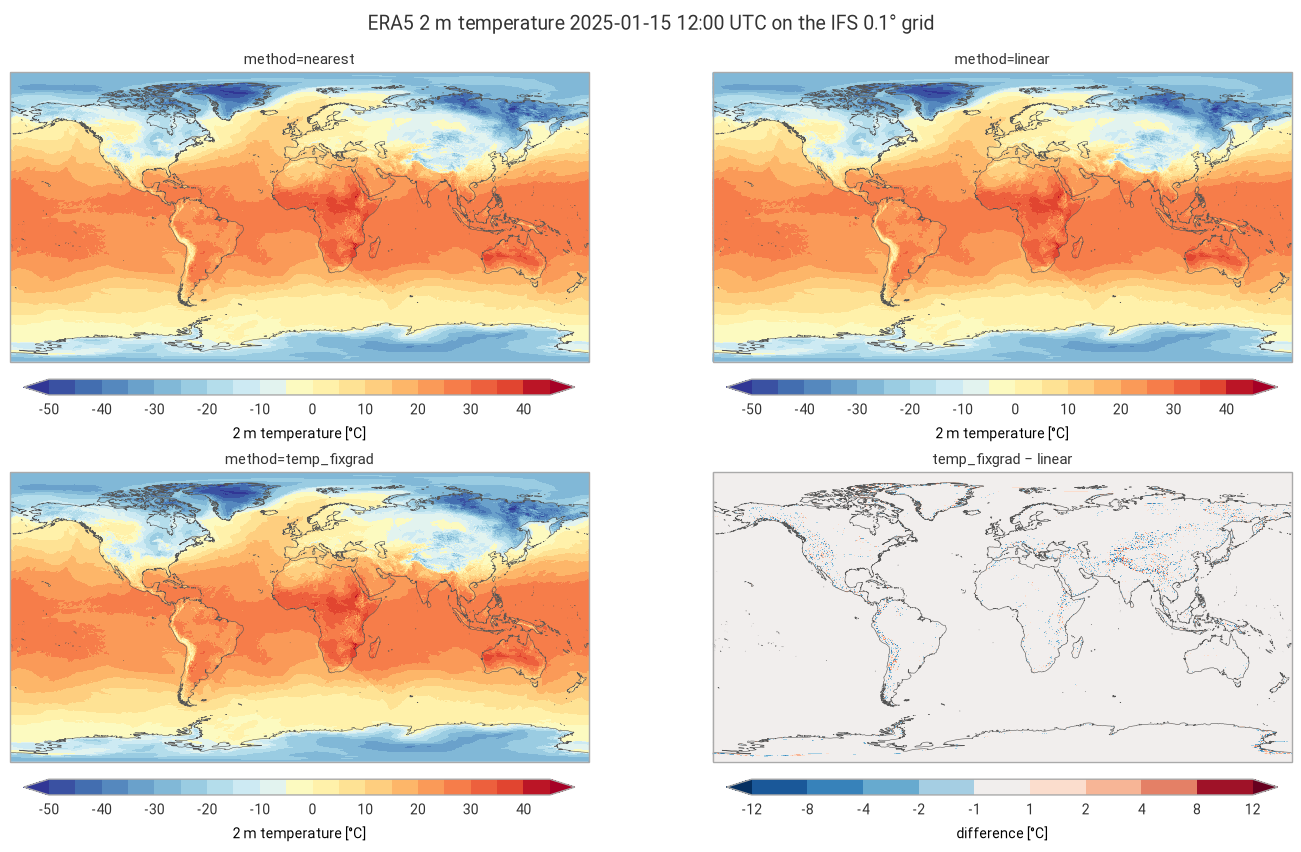

In [5]:
style = ekp.styles.Style(levels=np.arange(-50, 46, 5), colors="RdYlBu_r", extend="both", units="°C")
diff_style = ekp.styles.Style(levels=[-12, -8, -4, -2, -1, 1, 2, 4, 8, 12], colors="RdBu_r", extend="both", units="°C")
correction = results["temp_fixgrad"]["t2m"] - results["linear"]["t2m"]
panels = [(f"method={label}", results[label]["t2m"], style) for label in METHODS]
panels.append(("temp_fixgrad − linear", correction, diff_style))

fig = ekp.Figure(rows=2, columns=2, figsize=(14, 8), crs=ccrs.PlateCarree())
for i, (title, field, panel_style) in enumerate(panels):
    subplot = fig.add_map(i // 2, i % 2)
    subplot.pcolormesh(
        field.values, x=field.longitude.values, y=field.latitude.values, style=panel_style, transform=ccrs.PlateCarree()
    )
    subplot.coastlines(linewidth=0.4)
    subplot.title(title)
    subplot.legend(label="2 m temperature [°C]" if panel_style is style else "difference [°C]")
fig.title(f"ERA5 2 m temperature {ERA5_TIME.replace('T', ' ')} UTC on the IFS 0.1° grid")
fig.show()

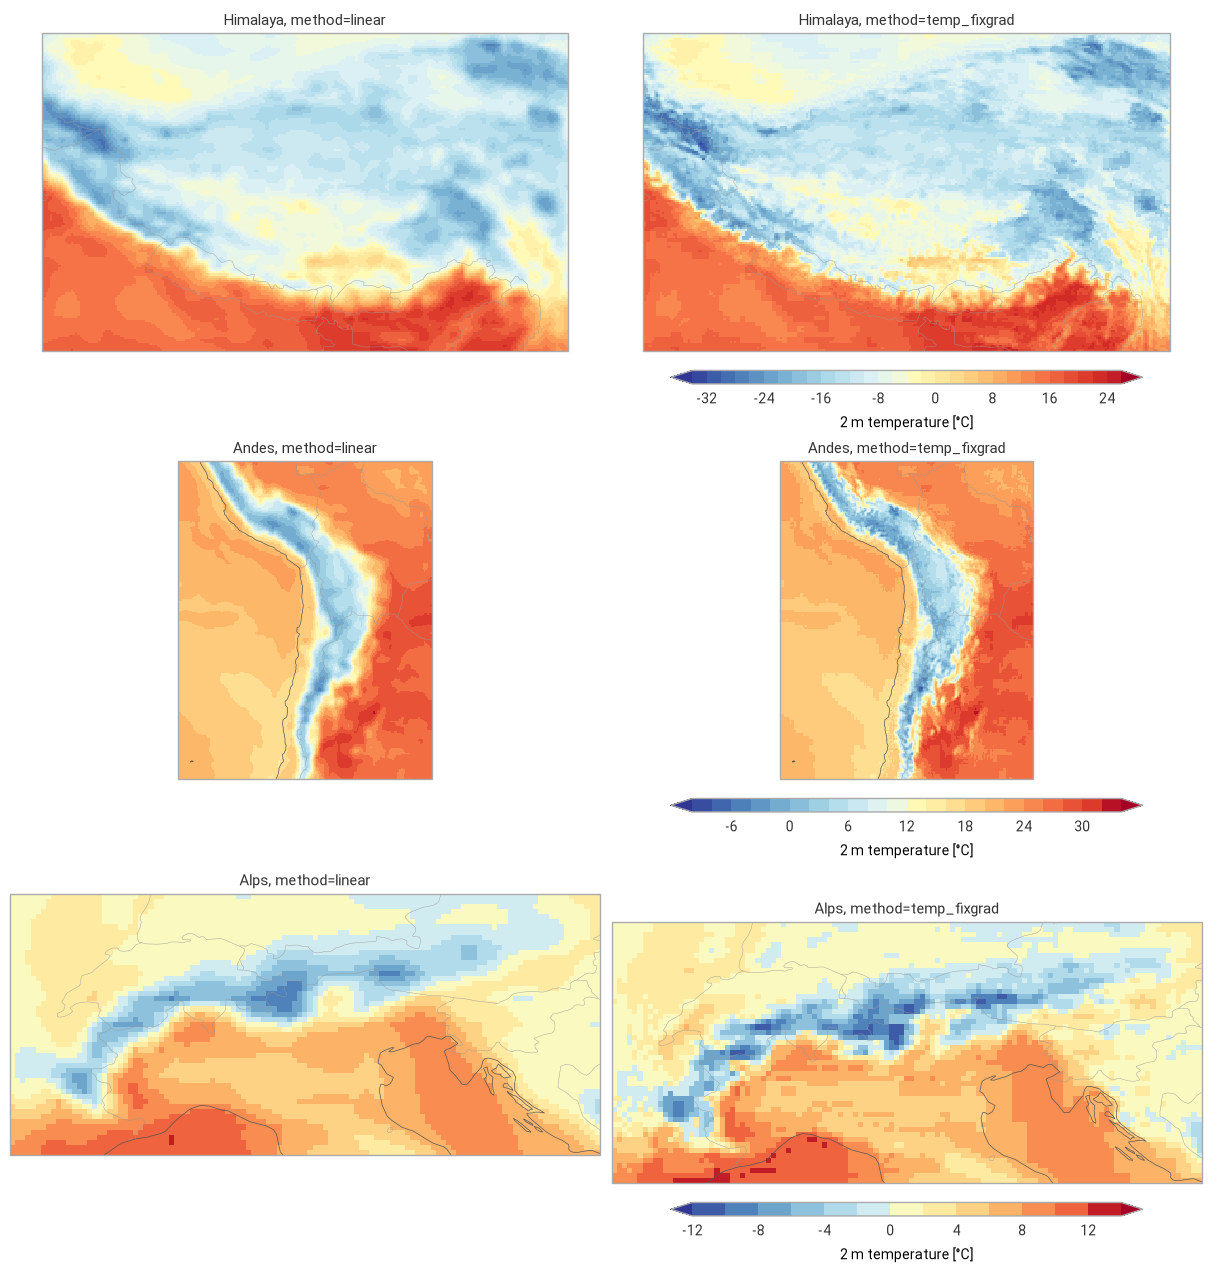

In [6]:
fig = ekp.Figure(rows=len(REGIONS), columns=2, figsize=(12, 4.2 * len(REGIONS)), crs=ccrs.PlateCarree())
for row, (region, (lon_bnds, lat_bnds)) in enumerate(REGIONS.items()):
    box = {"longitude": slice(*lon_bnds), "latitude": slice(*lat_bnds)}
    fields = [results[label]["t2m"].sel(box) for label in ("linear", "temp_fixgrad")]
    region_style = ekp.styles.Style(
        levels=np.arange(np.floor(min(f.min() for f in fields)), np.ceil(max(f.max() for f in fields)) + 2, 2),
        colors="RdYlBu_r",
        extend="both",
        units="°C",
    )
    for col, (label, field) in enumerate(zip(("linear", "temp_fixgrad"), fields)):
        subplot = fig.add_map(row, col)
        subplot.pcolormesh(
            field.values,
            x=field.longitude.values,
            y=field.latitude.values,
            style=region_style,
            transform=ccrs.PlateCarree(),
        )
        subplot.coastlines(linewidth=0.5)
        subplot.borders(linewidth=0.3)
        subplot.title(f"{region}, method={label}")
    subplot.legend(label="2 m temperature [°C]")
fig.show()

## Performance benchmark

The first call includes building the neighbor search structures and converting the coordinates, which
`grid_process` caches. Subsequent calls on the same grids (e.g. for other variables or times) reuse them:
their runtime is the mean ± standard deviation over 5 repetitions.

In [7]:
def benchmark(
    func: Callable[..., xr.Dataset],
    data: xr.Dataset,
    target: gpd.GeoDataFrame | xr.Dataset,
    methods: dict[str, dict[str, Any]],
    first_call_times: dict[str, float],
    repeat: int = 5,
) -> pd.DataFrame:
    """Runtime of the first call and mean ± standard deviation of the subsequent calls of each method."""
    rows: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        times = np.array(timeit.repeat(partial(func, data, target, **kw), number=1, repeat=repeat))
        rows[method] = {
            "first call [s]": f"{first_call_times[method]:.3f}",
            "subsequent calls [s]": f"{times.mean():.3f} ± {times.std():.3f}",
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("method")


print(
    f"{ds.latitude.size} × {ds.longitude.size} source grid points -> "
    f"{dst_grid.latitude.size} × {dst_grid.longitude.size} cells"
)
benchmark(gri.interp2grid, ds, dst_grid, runs, first_call)

721 × 1440 source grid points -> 1801 × 3600 cells


,first call [s],subsequent calls [s]
method,,
nearest,0.034,0.020 ± 0.001
linear,0.149,0.127 ± 0.001
temp_fixgrad,7.200,3.266 ± 0.022
nearest (try_reg=False),2.777,1.448 ± 0.003


## Takeaways

- `nearest` and `linear` keep the 0.25° (28 km) structure of ERA5: they ignore the more detailed
  orography of the 0.1° grid. `temp_fixgrad` corrects for the altitude difference between the source grid
  point and the destination cell, which brings back the terrain: cold ridges and warmer valleys in the
  Himalaya, the Andes and the Alps.
- The correction exceeds 1 °C in only 3 % of the cells worldwide, but in 14 to 31 % of the cells of the
  three mountain regions, mostly within ±5 °C. Over the oceans and plains the methods agree within
  about 1 °C; there `temp_fixgrad` takes a single source grid point, like `nearest`, while `linear`
  blends four.
- All cells get a value with every method, including across the 360° seam of the ERA5 grid (0 to 360°)
  in the -180 to 180° destination grid and at the poles.
- On a regular grid, `nearest` selects the same source point with the regular grid interpolation
  (`try_reg=True`, in degrees) and with the generic path in ECEF (`try_reg=False`), but about 70 times
  faster. The generic path is needed for the neighborhood methods (here `temp_fixgrad`) and irregular
  grids, whose neighbors must be searched in meters.
- Regridding 1 million source points to 6.5 million cells takes a fraction of a second with the regular
  grid interpolation. The generic path converts both grids to ECEF and builds the neighbor search at the
  first call (about 3 s for `nearest`, 7 s for `temp_fixgrad`), which subsequent calls reuse.